<a href="https://colab.research.google.com/github/Innej3/Synchronize/blob/main/ESN_rossler.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def watts_strogatz_laplacian(M, k, p, seed=42):
  '''
  M: number of nodes
  k: number of neighbors (k/2 each side)
  p: probability of rewiring, p=0 stay ring like
  '''
  rng = np.random.default_rng(seed)
  A = np.zeros((M, M), dtype=np.float64)
  halk_k = k // 2

  for i in range(M):
    for j in range(1, halk_k+1):
      target = (i + j) % M
      A[i, target] = 1.0
      A[target, i] = 1.0

  for i in range(M):
    for j in range(1, halk_k+1):
      if rng.random() < p:
        old_target = (i+j) % M
        available = np.where((A[i]==0) & (np.arange(M)!= i))[0]
        if len(available) > 0:
          new_target = rng.choice(available)
          A[i, old_target] = A[old_target, i] = 0.0
          A[i, new_target] = A[new_target, i] = 1.0

  # laplacian L = D - A
  D = np.diag(A.sum(axis=1))
  L = D - A
  return L

In [ ]:
M = np.zeros((3, 3))
M[0, 1] = M[1, 0] = 1.0
M[0, 2] = M[2, 0] = 1.0

np.diag(np.sum(M, axis=1))

array([[2., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

In [ ]:
def barabasi_albert_laplacian(M, m, seed=42):
  rng = np.random.default_rng(seed)
  A = np.zeros((M, M), dtype=np.float64)

  for i in range(m+1):
    for j in range(i+1, m+1):
      A[i, j] = A[j, i] = 1.0

  degrees = np.sum(A, axis=1)
  for new_node in range(m+1, M):
    probs = degrees[:new_node] / np.sum(degrees[:new_node])
    targets = rng.choice(new_node, size=m, replace=False, p=probs)
    for t in targets:
      A[new_node, t] = A[t, new_node] = 1.0
    degrees = np.sum(A, axis=1)

  # laplacian L = D - A
  D = np.diag(degrees)
  L = D - A
  return L, A


In [ ]:
def rossler_batch(S, L, eps, omega, a=0.2, b=0.2, c=5.7):
    x, y, z = S[..., 0], S[..., 1], S[..., 2]
    dx = -omega * y - z - eps * (x @ L.T)
    dy = omega * x + a * y
    dz = b + z * (x - c)
    return np.stack((dx, dy, dz), axis=-1)

In [ ]:
"""
Why we have transient time step i.e T_trans and why we discard it after?
-> lets understand this with an example suppose we whirpool happening in a tank
the whirpool is the attractor, and we drop 20 marbles in the tank, it will casuse
splashes and radom disturbance in water and the will marbles immediately start
spinning? No, it'll take some time untill it spins along the whirpool, so
having that data can pollute the calculation as its not needed its just noise,
so we drop it.

So below we are letting the calculation happend till transient period which we
are just gonna ignore it, the keep the other calculation for futher processing

Theres another reason why transient step is needed, since we are initializing
the position of the nodes randomly, the E_sync in the beginning gonna be
huge, and the coupling force takes some time to pull the oscialltors toward
each other, so if we take the average since the beginning, the E_sync will look
way larger than should be expected.

We can think of the transient as warm-up
"""

In [ ]:
def integrate_batch(L, eps, omega, B=10, dt=0.02, T_trans=200.0, T_keep=100.0, seed=0):
  rng = np.random.default_rng(seed)
  M = L.shape[0]

  S = rng.uniform(-2, 2, size=(B, M, 3))
  S[..., 2] = rng.uniform(0.1, 1.0, size=(B, M))
  n_tr, n_keep = int(T_trans / dt), int(T_keep / dt)
  traj = np.zeros((n_keep, B, M, 3))
  for t in range(n_tr + n_keep):
    k1 = rossler_batch(S, L, eps, omega)
    k2 = rossler_batch(S + 0.5 * dt * k1, L, eps, omega)
    k3 = rossler_batch(S + 0.5 * dt * k2, L, eps, omega)
    k4 = rossler_batch(S + dt * k3, L, eps, omega)
    S = S + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
    if t >= n_tr:
      traj[t-n_tr] = S

  return traj

In [ ]:
def metrics_batch(traj):
  # traj: (T, B, M, E)
  # sync error
  mf = traj.mean(axis=2, keepdims=True)
  E = np.sqrt(((traj-mf)**2).sum(-1).mean(-1).mean(0))
  # Kuramoto Phase Order
  theta = np.arctan2(traj[..., 1], traj[..., 0])
  R = np.abs(np.exp(1j*theta).mean(-1)).mean(0)
  return E, R

In [ ]:
'''
Master Stability Function (MSF)
"If I connect $M$ identical chaotic oscillators together in a network,
what coupling strength $\epsilon$ do I need so that they stay perfectly synchronized?"
DF - sigma * diag(1, 0, 0)


'''

In [ ]:
def msf(sigma, a=0.2, b=0.2, c=5.7, dt=0.01, T=800.0, T_trans=200.0):
  f = lambda s: np.array([-s[1] - s[2], s[0] + a * s[1], b + s[2] * (s[0] - c)])

  def rk4(s):
    k1 = f(s)
    k2 = f(s + dt/2*k1)
    k3 = f(s+dt/2*k2)
    k4 = f(s+dt*k3)
    return s + dt/6*(k1+2*k2+2*k3+k4)
  s = np.array([1.0, 1.0, 0.5])
  for _ in range(int(T_trans/dt)):
    s = rk4(s)

  # Initialize v as a random 3D vector for the tangent space
  v = np.array([1.0, 0.0, 0.0])
  acc = 0.0

  for i in range(int(T/dt)):
    # Jacobian matrix J
    J = np.array([[-sigma, -1, -1], [1, a, 0], [s[2], 0, s[0] - c]])
    v = v + dt * (J @ v)
    s = rk4(s)
    if i % 10 == 0:
      n = np.linalg.norm(v)
      acc += np.log(n)
      v /= n
  return acc / T

In [ ]:
def msf_zero(lo, hi, tol=1e-3):
  s_lo = np.sign(msf(lo))
  while hi - lo > tol:
    mid = 0.5 * (lo + hi)
    if np.sign(msf(mid)) == s_lo:
      lo = mid
    else:
      hi = mid
  return 0.5 * (lo + hi)

In [ ]:
M = 50
L = watts_strogatz_laplacian(M, k=6, p=0.15)
lam = np.sort(np.linalg.eigvalsh(L))
lam2, lamN = lam[1], lam[-1]

sig1, sig2 = msf_zero(0.05, 0.3), msf_zero(3.0, 6.0)
eps_lo, eps_hi = sig1 / lam2, sig2 / lamN
print(f"lambda2={lam2:.3f} lambdaN={lamN:.3f}  MSF<0 for {sig1:.3f}<sigma<{sig2:.3f}")
print(f"complete sync predicted for {eps_lo:.3f} < eps < {eps_hi:.3f}")

lambda2=0.819 lambdaN=10.826  MSF<0 for 0.143<sigma<4.440
complete sync predicted for 0.175 < eps < 0.410


In [ ]:
eps_values = np.round(np.arange(0.0, 0.4401, 0.02), 3)
omega_id = np.ones(M)
omega_het = np.random.default_rng(42).uniform(0.99, 1.01, M)
res = {}
for name, om in [("identical", omega_id), ("1% mismatch", omega_het)]:
  E_m, E_s, R_m, R_s = [], [], [], []
  for eps in eps_values:
    E, R = metrics_batch(integrate_batch(L, eps, om, B=10))
    E_m.append(E.mean()); E_s.append(E.std())
    R_m.append(R.mean()); R_s.append(R.std())
    print(f"{name:12s} eps={eps:.3f}  E={E.mean():.3f}+-{E.std():.3f}  R={R.mean():.3f}+-{R.std():.3f}")
  res[name] = [np.array(v) for v in (E_m, E_s, R_m, R_s)]


identical    eps=0.000  E=7.556+-0.047  R=0.143+-0.040
identical    eps=0.020  E=4.436+-1.726  R=0.796+-0.235
identical    eps=0.040  E=2.710+-0.075  R=0.979+-0.003
identical    eps=0.060  E=2.514+-0.142  R=0.982+-0.001
identical    eps=0.080  E=2.279+-0.390  R=0.983+-0.005
identical    eps=0.100  E=2.244+-0.310  R=0.984+-0.005
identical    eps=0.120  E=1.956+-0.898  R=0.987+-0.007
identical    eps=0.140  E=1.552+-1.018  R=0.991+-0.007
identical    eps=0.160  E=1.341+-0.924  R=0.992+-0.006
identical    eps=0.180  E=0.888+-1.137  R=0.995+-0.007
identical    eps=0.200  E=0.472+-0.564  R=0.998+-0.003
identical    eps=0.220  E=0.039+-0.067  R=1.000+-0.000
identical    eps=0.240  E=0.009+-0.022  R=1.000+-0.000
identical    eps=0.260  E=0.009+-0.026  R=1.000+-0.000
identical    eps=0.280  E=0.005+-0.010  R=1.000+-0.000
identical    eps=0.300  E=0.001+-0.004  R=1.000+-0.000
identical    eps=0.320  E=0.000+-0.000  R=1.000+-0.000
identical    eps=0.340  E=0.000+-0.000  R=1.000+-0.000
identical 

/tmp/ipykernel_3292/3621276677.py:5: RuntimeWarning: overflow encountered in multiply
  dz = b + z * (x - c)
/tmp/ipykernel_3292/3621276677.py:3: RuntimeWarning: invalid value encountered in matmul
  dx = -omega * y - z - eps * (x @ L.T)
/tmp/ipykernel_3292/3921164609.py:14: RuntimeWarning: invalid value encountered in add
  S = S + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
/tmp/ipykernel_3292/3921164609.py:11: RuntimeWarning: invalid value encountered in add
  k2 = rossler_batch(S + 0.5 * dt * k1, L, eps, omega)
/tmp/ipykernel_3292/3621276677.py:3: RuntimeWarning: invalid value encountered in subtract
  dx = -omega * y - z - eps * (x @ L.T)
/tmp/ipykernel_3292/4260358106.py:5: RuntimeWarning: invalid value encountered in subtract
  E = np.sqrt(((traj-mf)**2).sum(-1).mean(-1).mean(0))
/tmp/ipykernel_3292/4260358106.py:5: RuntimeWarning: overflow encountered in square
  E = np.sqrt(((traj-mf)**2).sum(-1).mean(-1).mean(0))
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:13

identical    eps=0.440  E=nan+-nan  R=nan+-nan
1% mismatch  eps=0.000  E=7.556+-0.033  R=0.114+-0.020
1% mismatch  eps=0.020  E=4.303+-1.372  R=0.835+-0.173
1% mismatch  eps=0.040  E=2.801+-0.083  R=0.976+-0.004
1% mismatch  eps=0.060  E=2.523+-0.179  R=0.981+-0.002
1% mismatch  eps=0.080  E=2.437+-0.275  R=0.981+-0.002
1% mismatch  eps=0.100  E=2.351+-0.260  R=0.982+-0.004
1% mismatch  eps=0.120  E=1.975+-0.826  R=0.987+-0.006
1% mismatch  eps=0.140  E=1.187+-0.790  R=0.993+-0.006
1% mismatch  eps=0.160  E=1.058+-0.938  R=0.994+-0.006
1% mismatch  eps=0.180  E=1.285+-0.798  R=0.992+-0.006
1% mismatch  eps=0.200  E=0.707+-0.752  R=0.997+-0.005
1% mismatch  eps=0.220  E=0.463+-0.618  R=0.998+-0.004
1% mismatch  eps=0.240  E=0.356+-0.531  R=0.999+-0.003
1% mismatch  eps=0.260  E=0.148+-0.004  R=1.000+-0.000
1% mismatch  eps=0.280  E=0.138+-0.005  R=1.000+-0.000
1% mismatch  eps=0.300  E=0.128+-0.005  R=1.000+-0.000
1% mismatch  eps=0.320  E=0.121+-0.005  R=1.000+-0.000
1% mismatch  eps=0

/tmp/ipykernel_3292/3921164609.py:12: RuntimeWarning: invalid value encountered in add
  k3 = rossler_batch(S + 0.5 * dt * k2, L, eps, omega)
/tmp/ipykernel_3292/3621276677.py:4: RuntimeWarning: invalid value encountered in add
  dy = omega * x + a * y


1% mismatch  eps=0.440  E=nan+-nan  R=nan+-nan


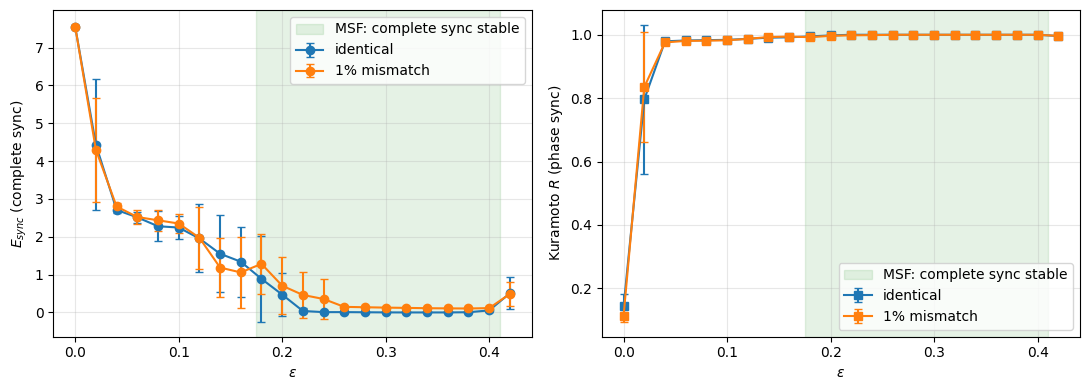

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, (E_m, E_s, R_m, R_s) in res.items():
  axes[0].errorbar(eps_values, E_m, E_s, marker='o', capsize=3, label=name)
  axes[1].errorbar(eps_values, R_m, R_s, marker='s', capsize=3, label=name)
for ax in axes:
  ax.axvspan(eps_lo, eps_hi, color='green', alpha=0.1, label='MSF: complete sync stable')
  ax.set_xlabel(r'$\epsilon$'); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel(r'$E_{sync}$ (complete sync)')
axes[1].set_ylabel(r'Kuramoto $R$ (phase sync)')
plt.tight_layout(); plt.show()

In [ ]:
class PAESN:
  def __init__(self, D_in=3, N=600, rho=0.9, alpha=0.5, density=0.05, sigma_in=0.3,
               sigma_eps=0.2, eps_k=5.0, eps_bias=-0.25, lam=1e-4, noise=0.02, seed=0):
    rng = np.random.default_rng(seed)
    W = rng.uniform(-1, 1, (N, N)) * (rng.random((N, N)) < density)
    self.W = W * rho / np.max(np.abs(np.linalg.eigvals(W)))
    self.W_in = rng.uniform(-sigma_in, sigma_in, (N, D_in))
    self.b = rng.uniform(-sigma_eps, sigma_eps, N)
    self.N = N
    self.alpha = alpha
    self.lam = lam
    self.noise = noise
    self.rng = rng
    self.eps_k = eps_k
    self.eps_bias = eps_bias

  def scale_eps(self, eps):
    return self.eps_k * eps + self.eps_bias

  def step(self, r, u, eps):
    pre = self.W @ r + self.W_in @ u + self.scale_eps(eps) * self.b
    return (1 - self.alpha) * r + self.alpha * np.tanh(pre)

  def feat(self, r):
    f = r.copy()
    f[1::2] = f[1::2]**2
    return np.append(f, 1.0)

  def fit(self, series, eps_list, washout=200):
    allu = np.vstack(series)
    self.mu, self.sd = allu.mean(0), allu.std(0)

    X, Y = [], []
    for u, eps in zip(series, eps_list):
      un = (u - self.mu) / self.sd
      r = np.zeros(self.N)
      for t in range(len(un) - 1):
        r = self.step(r, un[t] + self.rng.normal(0, self.noise, un.shape[1]), eps)
        if t >= washout:
          X.append(self.feat(r))
          Y.append(un[t+1])
    X, Y = np.array(X), np.array(Y)
    self.W_out =  np.linalg.solve(X.T @ X + self.lam * np.eye(X.shape[1]), X.T @ Y).T

  def predict(self, u_warm, eps, n):
    r = np.zeros(self.N)
    for u in (u_warm - self.mu) / self.sd:
      r = self.step(r, u, eps)
    v = self.W_out @ self.feat(r)
    out = np.zeros((n, len(v)))
    for t in range(n):
      out[t] = v
      r = self.step(r, v, eps)
      v = self.W_out @ self.feat(r)
    return out * self.sd + self.mu

In [ ]:
M = 50
L = watts_strogatz_laplacian(M, k=6, p=0.15)
omega = np.ones(M)
sub = 3

def mean_field(eps, seed, T_keep=400.0):
  tr = integrate_batch(L, eps, omega, B=1, T_trans=300.0, T_keep=T_keep, seed=seed)
  return tr.mean(axis=2)[::sub, 0, :]       # shape (T, 3)

train_eps = [0.10, 0.12, 0.14, 0.16]
train = [mean_field(e, seed=i, T_keep=600.0) for i, e in enumerate(train_eps)]

test_eps = [0.10, 0.12, 0.14, 0.16, 0.18, 0.20, 0.22, 0.25, 0.30]
n_real = 10
test = {e: [mean_field(e, seed=100 + k, T_keep=250.0) for k in range(n_real)] for e in test_eps}
truth = {e: np.array([u[:, 2].std() for u in test[e]]) for e in test_eps}

In [ ]:
n_res = 10
pred = np.full((n_res, len(test_eps)), np.nan)
status = np.empty((n_res, len(test_eps)), dtype=object)

for s in range(n_res):
  esn = PAESN(seed=s)
  esn.fit(train, train_eps)
  for i, e in enumerate(test_eps):
    p = esn.predict(test[e][0][:300], e, 3000)
    if not np.all(np.isfinite(p)) or np.abs(p).max() > 100:
      status[s, i] = 'blowup'
      continue
    z = p[500:, 2].std()
    pred[s, i] = z
    status[s, i] = 'collapse' if z < 0.3 else 'ok'
  print(f"reservoir {s} done")

reservoir 0 done
reservoir 1 done
reservoir 2 done
reservoir 3 done
reservoir 4 done
reservoir 5 done
reservoir 6 done
reservoir 7 done
reservoir 8 done
reservoir 9 done


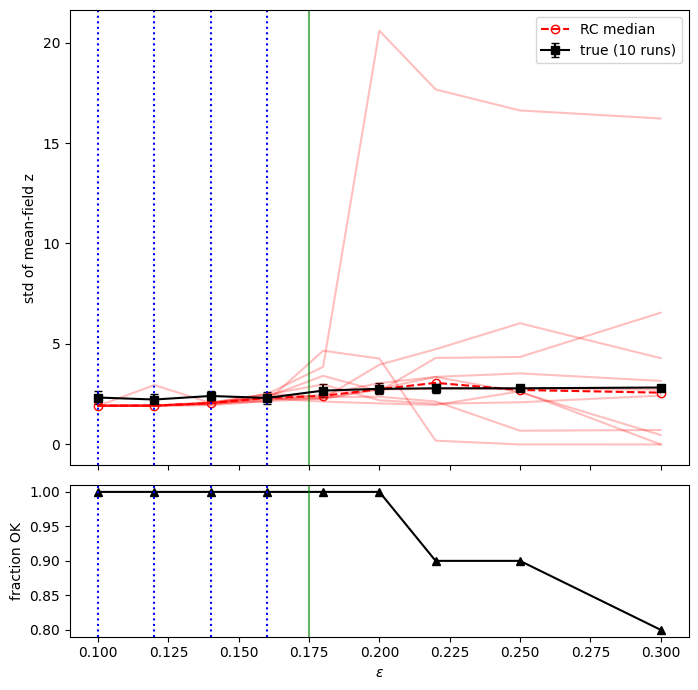

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 7), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1]})
t_mean = np.array([truth[e].mean() for e in test_eps])
t_std = np.array([truth[e].std() for e in test_eps])
ax1.errorbar(test_eps, t_mean, t_std, fmt='ks-', capsize=3, label='true (10 runs)')
for s in range(n_res):
  ax1.plot(test_eps, pred[s], 'r-', alpha=0.25)
ax1.plot(test_eps, np.nanmedian(pred, 0), 'ro--', mfc='none', label='RC median')
ax1.set_ylabel('std of mean-field z')
ax1.legend()

ok_frac = np.mean(status == 'ok', axis=0)
ax2.plot(test_eps, ok_frac, 'k^-')
ax2.set_ylabel('fraction OK')
ax2.set_xlabel(r'$\epsilon$')

for ax in (ax1, ax2):
  for e in train_eps:
    ax.axvline(e, ls=':', c='b')
  ax.axvline(0.175, c='green', alpha=0.6)   # MSF onset of complete sync
plt.tight_layout(); plt.show()

In [ ]:
def run_setting(eps_bias, n_res=6, n_warm=3):
  pred = np.full((n_res, len(test_eps)), np.nan)
  status = np.empty((n_res, len(test_eps)), dtype=object)
  for s in range(n_res):
    esn = PAESN(seed=s, eps_bias=eps_bias)
    esn.fit(train, train_eps)
    for i, e in enumerate(test_eps):
      zs, bad = [], False
      for k in range(n_warm):
        p = esn.predict(test[e][k][:300], e, 3000)
        if not np.all(np.isfinite(p)) or np.abs(p).max() > 100:
          bad = True
          break
        zs.append(p[500:, 2].std())
      if bad:
        status[s, i] = 'blowup'
        continue
      z = np.mean(zs)
      pred[s, i] = z
      tv = truth[e].mean()
      status[s, i] = 'collapse' if z < 0.3 else ('runaway' if z > 1.5 * tv else 'ok')
  return pred, status

In [ ]:
pred, status = run_setting(-0.25, n_res=20, n_warm=3)
print("all   ", np.round(np.nanmedian(pred, 0), 2))
print("0-9   ", np.round(np.nanmedian(pred[:10], 0), 2))
print("10-19 ", np.round(np.nanmedian(pred[10:], 0), 2))
print("truth ", np.round([truth[e].mean() for e in test_eps], 2))
print("ok    ", np.round(np.mean(status == 'ok', 0), 2))

all    [1.93 1.93 2.06 2.27 2.35 2.59 2.71 2.81 2.7 ]
0-9    [1.93 1.93 2.06 2.3  2.33 2.75 3.03 2.76 2.55]
10-19  [1.92 1.93 2.06 2.25 2.39 2.45 2.6  2.9  2.82]
truth  [2.33 2.24 2.41 2.31 2.68 2.77 2.79 2.79 2.83]
ok     [1.  1.  1.  1.  1.  0.9 0.8 0.8 0.6]


In [ ]:
ctrl_train_eps = [0.04, 0.06, 0.08, 0.10]
ctrl_train = [mean_field(e, seed=i, T_keep=600.0) for i, e in enumerate(ctrl_train_eps)]
ctrl_test_eps = [0.04, 0.06, 0.08, 0.10, 0.12, 0.14, 0.16]
ctrl_test = {e: [mean_field(e, seed=200 + k, T_keep=250.0) for k in range(5)] for e in ctrl_test_eps}
ctrl_truth = {e: np.mean([u[:, 2].std() for u in ctrl_test[e]]) for e in ctrl_test_eps}

P = np.full((20, len(ctrl_test_eps)), np.nan)
for s in range(20):
  esn = PAESN(seed=s, eps_bias=-0.25)
  esn.fit(ctrl_train, ctrl_train_eps)
  for i, e in enumerate(ctrl_test_eps):
    zs = []
    for k in range(3):
      p = esn.predict(ctrl_test[e][k][:300], e, 3000)
      if not np.all(np.isfinite(p)) or np.abs(p).max() > 100:
        zs = None
        break
      zs.append(p[500:, 2].std())
    P[s, i] = np.nan if zs is None else np.mean(zs)

print("eps   ", ctrl_test_eps)
print("truth ", np.round([ctrl_truth[e] for e in ctrl_test_eps], 2))
print("median", np.round(np.nanmedian(P, 0), 2))

eps    [0.04, 0.06, 0.08, 0.1, 0.12, 0.14, 0.16]
truth  [1.98 2.   2.07 2.14 2.27 2.55 2.36]
median [1.91 1.95 2.04 2.04 2.08 2.08 2.1 ]


fraction of time E_sync < 0.5: 0.07


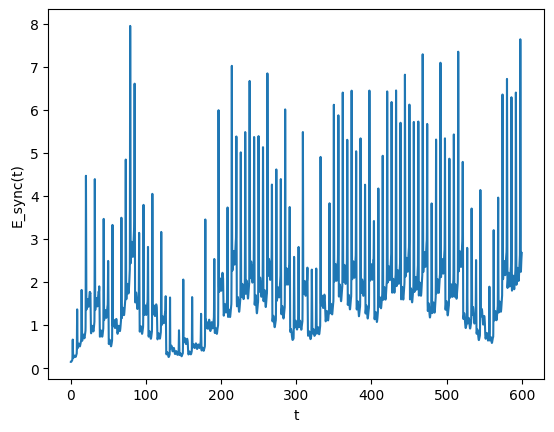

In [ ]:
tr = integrate_batch(L, 0.16, omega, B=1, T_trans=300.0, T_keep=600.0, seed=3)  # same seed as train[3]
mf = tr.mean(axis=2, keepdims=True)
E_t = np.sqrt(((tr - mf)**2).sum(-1).mean(-1))[:, 0]
print("fraction of time E_sync < 0.5:", np.mean(E_t < 0.5).round(2))
plt.plot(np.arange(len(E_t)) * 0.02, E_t); plt.xlabel('t'); plt.ylabel('E_sync(t)'); plt.show()

In [ ]:
tr3 = train[:3]; te3 = train_eps[:3]
P = np.full((20, len(test_eps)), np.nan)
for s in range(20):
  esn = PAESN(seed=s, eps_bias=-0.25)
  esn.fit(tr3, te3)
  for i, e in enumerate(test_eps):
    zs = []
    for k in range(3):
      p = esn.predict(test[e][k][:300], e, 3000)
      if not np.all(np.isfinite(p)) or np.abs(p).max() > 100:
        zs = None
        break
      zs.append(p[500:, 2].std())
    P[s, i] = np.nan if zs is None else np.mean(zs)
print("median", np.round(np.nanmedian(P, 0), 2))

median [1.93 1.93 2.05 2.24 2.34 2.46 3.37 2.07 2.96]


In [ ]:
eps_scan = [0.04, 0.08, 0.10, 0.12, 0.14, 0.16, 0.17]
for e in eps_scan:
  tr = integrate_batch(L, e, omega, B=5, T_trans=300.0, T_keep=400.0, seed=500)
  mf = tr.mean(axis=2, keepdims=True)
  E_t = np.sqrt(((tr - mf)**2).sum(-1).mean(-1))    # (T, B)
  frac = (E_t < 1.0).mean(axis=0)                    # per realization
  print(f"eps={e:.2f}  near-sync fraction {frac.mean():.2f} +- {frac.std():.2f}   median E {np.median(E_t):.2f}")

eps=0.04  near-sync fraction 0.00 +- 0.00   median E 2.20
eps=0.08  near-sync fraction 0.03 +- 0.02   median E 2.01
eps=0.10  near-sync fraction 0.05 +- 0.04   median E 1.90
eps=0.12  near-sync fraction 0.44 +- 0.34   median E 1.22
eps=0.14  near-sync fraction 0.24 +- 0.18   median E 1.53
eps=0.16  near-sync fraction 0.66 +- 0.19   median E 0.27
eps=0.17  near-sync fraction 0.69 +- 0.26   median E 0.12


In [ ]:
eps_scan = [0.04, 0.08, 0.10, 0.11, 0.12, 0.13, 0.14, 0.16, 0.17]
thresholds = [0.5, 1.0, 2.0]
for e in eps_scan:
  tr = integrate_batch(L, e, omega, B=20, T_trans=300.0, T_keep=400.0, seed=600)
  mf = tr.mean(axis=2, keepdims=True)
  E_t = np.sqrt(((tr - mf)**2).sum(-1).mean(-1))     # (T, B)
  row = "  ".join(f"<{th}: {(E_t < th).mean(0).mean():.2f}±{(E_t < th).mean(0).std():.2f}" for th in thresholds)
  print(f"eps={e:.2f}  {row}")

eps=0.04  <0.5: 0.00±0.00  <1.0: 0.00±0.00  <2.0: 0.35±0.05
eps=0.08  <0.5: 0.01±0.04  <1.0: 0.05±0.07  <2.0: 0.52±0.07
eps=0.10  <0.5: 0.04±0.10  <1.0: 0.11±0.12  <2.0: 0.59±0.09
eps=0.11  <0.5: 0.08±0.19  <1.0: 0.18±0.22  <2.0: 0.60±0.16
eps=0.12  <0.5: 0.14±0.26  <1.0: 0.24±0.27  <2.0: 0.66±0.15
eps=0.13  <0.5: 0.21±0.34  <1.0: 0.31±0.33  <2.0: 0.69±0.19
eps=0.14  <0.5: 0.27±0.37  <1.0: 0.39±0.36  <2.0: 0.73±0.20
eps=0.16  <0.5: 0.51±0.40  <1.0: 0.59±0.38  <2.0: 0.81±0.21
eps=0.17  <0.5: 0.60±0.36  <1.0: 0.68±0.33  <2.0: 0.86±0.16


In [ ]:
windows = {
  "0.06-0.10 (none)":   [0.06, 0.08, 0.10],
  "0.08-0.12 (edge)":   [0.08, 0.10, 0.12],
  "0.10-0.14 (inside)": [0.10, 0.12, 0.14],
}
eval_eps = [0.14, 0.16, 0.18, 0.20, 0.22]
fresh = {e: [mean_field(e, seed=900 + k, T_keep=250.0) for k in range(5)] for e in eval_eps}
fresh_truth = {e: np.mean([u[:, 2].std() for u in fresh[e]]) for e in eval_eps}
print("truth  ", np.round([fresh_truth[e] for e in eval_eps], 2))

win_results = {}
for name, w_eps in windows.items():
  w_train = [mean_field(e, seed=300 + i, T_keep=600.0) for i, e in enumerate(w_eps)]
  bias = -5.0 * np.mean(w_eps)          # centre each window at 0, same rule for all
  P = np.full((20, len(eval_eps)), np.nan)
  for s in range(20):
    esn = PAESN(seed=s, eps_bias=bias)
    esn.fit(w_train, w_eps)
    for i, e in enumerate(eval_eps):
      zs = []
      for k in range(3):
        p = esn.predict(fresh[e][k][:300], e, 3000)
        if not np.all(np.isfinite(p)) or np.abs(p).max() > 100:
          zs = None
          break
        zs.append(p[500:, 2].std())
      P[s, i] = np.nan if zs is None else np.mean(zs)
  win_results[name] = P
  med = np.nanmedian(P, 0)
  print(f"{name:20s} median {np.round(med, 2)}   halves: {np.round(np.nanmedian(P[:10],0),2)} / {np.round(np.nanmedian(P[10:],0),2)}")

truth   [2.59 2.72 2.85 2.78 2.89]
0.06-0.10 (none)     median [1.97 1.6  1.15 1.15 0.62]   halves: [1.44 1.07 0.73 0.85 0.23] / [2.61 2.18 2.13 1.8  1.19]
0.08-0.12 (edge)     median [2.3  2.02 1.98 2.02 2.18]   halves: [2.6  2.05 2.12 1.63 1.9 ] / [1.94 1.97 1.84 2.15 2.18]
0.10-0.14 (inside)   median [2.69 3.1  2.05 1.42 1.02]   halves: [2.75 3.3  1.08 1.24 0.94] / [2.6  2.99 2.33 1.79 1.24]


In [ ]:
from scipy.signal import find_peaks

for e in eps_scan:
  tr = integrate_batch(L, e, omega, B=10, T_trans=300.0, T_keep=400.0, seed=700)
  mf = tr.mean(axis=2, keepdims=True)
  E_t = np.sqrt(((tr - mf)**2).sum(-1).mean(-1))          # (T, B), needs full state
  z = mf[..., 0, 2]                                          # (T, B), mean field only
  tall, near = [], []
  for b in range(z.shape[1]):
    pk, _ = find_peaks(z[:, b], height=1.0)
    tall.append(np.mean(z[pk, b] > 10.0) if len(pk) else 0.0)
    near.append(np.mean(E_t[:, b] < 1.0))
  r = np.corrcoef(tall, near)[0, 1] if np.std(tall) > 0 else np.nan
  print(f"eps={e:.2f}  tall-peak frac {np.mean(tall):.2f}  near-sync frac {np.mean(near):.2f}  corr across runs {r:.2f}")

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


eps=0.04  tall-peak frac 0.09  near-sync frac 0.00  corr across runs nan
eps=0.08  tall-peak frac 0.21  near-sync frac 0.10  corr across runs 0.95
eps=0.10  tall-peak frac 0.22  near-sync frac 0.06  corr across runs 0.29
eps=0.11  tall-peak frac 0.27  near-sync frac 0.17  corr across runs 0.60
eps=0.12  tall-peak frac 0.35  near-sync frac 0.25  corr across runs 0.85
eps=0.13  tall-peak frac 0.32  near-sync frac 0.34  corr across runs 0.74
eps=0.14  tall-peak frac 0.34  near-sync frac 0.29  corr across runs 0.89
eps=0.16  tall-peak frac 0.40  near-sync frac 0.59  corr across runs 0.84
eps=0.17  tall-peak frac 0.41  near-sync frac 0.57  corr across runs 0.94


In [ ]:
from scipy.signal import find_peaks

thresholds = [8.0, 10.0, 12.0]

for e in eps_scan:
  tr = integrate_batch(L, e, omega, B=20, T_trans=300.0, T_keep=400.0, seed=800)
  mf = tr.mean(axis=2, keepdims=True)
  E_t = np.sqrt(((tr - mf)**2).sum(-1).mean(-1))     # (T, B) needs all nodes
  z = mf[..., 0, 2]                                     # (T, B) average signal only
  near = np.array([np.mean(E_t[:, b] < 1.0) for b in range(z.shape[1])])

  parts = []
  for th in thresholds:
    tall = []
    for b in range(z.shape[1]):
      pk, _ = find_peaks(z[:, b], height=1.0)
      tall.append(np.mean(z[pk, b] > th) if len(pk) else 0.0)
    tall = np.array(tall)
    r = np.corrcoef(tall, near)[0, 1] if np.std(tall) > 0 and np.std(near) > 0 else np.nan
    parts.append(f">{th:.0f}: {tall.mean():.2f} (r={r:.2f})")
  print(f"eps={e:.2f}  near-sync {near.mean():.2f}   " + "   ".join(parts))

eps=0.04  near-sync 0.00   >8: 0.37 (r=0.21)   >10: 0.12 (r=0.21)   >12: 0.02 (r=0.34)
eps=0.08  near-sync 0.04   >8: 0.42 (r=0.33)   >10: 0.24 (r=0.60)   >12: 0.11 (r=0.83)
eps=0.10  near-sync 0.06   >8: 0.42 (r=0.38)   >10: 0.22 (r=0.61)   >12: 0.11 (r=0.81)
eps=0.11  near-sync 0.19   >8: 0.44 (r=0.74)   >10: 0.30 (r=0.75)   >12: 0.18 (r=0.90)
eps=0.12  near-sync 0.31   >8: 0.47 (r=0.89)   >10: 0.32 (r=0.88)   >12: 0.25 (r=0.94)
eps=0.13  near-sync 0.29   >8: 0.46 (r=0.88)   >10: 0.32 (r=0.90)   >12: 0.22 (r=0.96)
eps=0.14  near-sync 0.36   >8: 0.49 (r=0.90)   >10: 0.36 (r=0.90)   >12: 0.26 (r=0.94)
eps=0.16  near-sync 0.58   >8: 0.53 (r=0.89)   >10: 0.43 (r=0.90)   >12: 0.34 (r=0.90)
eps=0.17  near-sync 0.56   >8: 0.50 (r=0.86)   >10: 0.39 (r=0.88)   >12: 0.31 (r=0.93)


In [ ]:
thresholds = [8.0, 10.0, 12.0]

for e in eps_scan:
  tr = integrate_batch(L, e, omega, B=10, T_trans=300.0, T_keep=400.0, seed=800)
  mf = tr.mean(axis=2, keepdims=True)
  E_t = np.sqrt(((tr - mf)**2).sum(-1).mean(-1))     # (T, B) needs all nodes
  z = mf[..., 0, 2]                                     # (T, B) average signal only
  near = np.array([np.mean(E_t[:, b] < 1.0) for b in range(z.shape[1])])

  parts = []
  for th in thresholds:
    tall = []
    for b in range(z.shape[1]):
      pk, _ = find_peaks(z[:, b], height=1.0)
      tall.append(np.mean(z[pk, b] > th) if len(pk) else 0.0)
    tall = np.array(tall)
    r = np.corrcoef(tall, near)[0, 1] if np.std(tall) > 0 and np.std(near) > 0 else np.nan
    parts.append(f">{th:.0f}: {tall.mean():.2f} (r={r:.2f})")
  print(f"eps={e:.2f}  near-sync {near.mean():.2f}   " + "   ".join(parts))

eps=0.04  near-sync 0.00   >8: 0.34 (r=nan)   >10: 0.06 (r=nan)   >12: 0.01 (r=nan)
eps=0.08  near-sync 0.04   >8: 0.42 (r=0.56)   >10: 0.22 (r=0.47)   >12: 0.10 (r=0.46)
eps=0.10  near-sync 0.18   >8: 0.44 (r=0.75)   >10: 0.30 (r=0.79)   >12: 0.19 (r=0.80)
eps=0.11  near-sync 0.15   >8: 0.43 (r=0.60)   >10: 0.25 (r=0.36)   >12: 0.15 (r=0.73)
eps=0.12  near-sync 0.10   >8: 0.41 (r=0.60)   >10: 0.21 (r=0.63)   >12: 0.12 (r=0.80)
eps=0.13  near-sync 0.39   >8: 0.51 (r=0.91)   >10: 0.38 (r=0.93)   >12: 0.29 (r=0.93)
eps=0.14  near-sync 0.33   >8: 0.50 (r=0.75)   >10: 0.36 (r=0.88)   >12: 0.26 (r=0.90)
eps=0.16  near-sync 0.61   >8: 0.54 (r=0.89)   >10: 0.42 (r=0.97)   >12: 0.35 (r=0.96)
eps=0.17  near-sync 0.73   >8: 0.55 (r=0.93)   >10: 0.47 (r=0.95)   >12: 0.41 (r=0.95)


In [ ]:
thresholds = [8.0, 10.0, 12.0]

for e in eps_scan:
  tr = integrate_batch(L, e, omega, B=8, T_trans=300.0, T_keep=400.0, seed=800)
  mf = tr.mean(axis=2, keepdims=True)
  E_t = np.sqrt(((tr - mf)**2).sum(-1).mean(-1))     # (T, B) needs all nodes
  z = mf[..., 0, 2]                                     # (T, B) average signal only
  near = np.array([np.mean(E_t[:, b] < 1.0) for b in range(z.shape[1])])

  parts = []
  for th in thresholds:
    tall = []
    for b in range(z.shape[1]):
      pk, _ = find_peaks(z[:, b], height=1.0)
      tall.append(np.mean(z[pk, b] > th) if len(pk) else 0.0)
    tall = np.array(tall)
    r = np.corrcoef(tall, near)[0, 1] if np.std(tall) > 0 and np.std(near) > 0 else np.nan
    parts.append(f">{th:.0f}: {tall.mean():.2f} (r={r:.2f})")
  print(f"eps={e:.2f}  near-sync {near.mean():.2f}   " + "   ".join(parts))

eps=0.04  near-sync 0.00   >8: 0.35 (r=nan)   >10: 0.11 (r=nan)   >12: 0.01 (r=nan)
eps=0.08  near-sync 0.05   >8: 0.41 (r=0.89)   >10: 0.19 (r=0.65)   >12: 0.09 (r=0.70)
eps=0.10  near-sync 0.11   >8: 0.42 (r=0.90)   >10: 0.25 (r=0.90)   >12: 0.13 (r=0.92)
eps=0.11  near-sync 0.14   >8: 0.44 (r=0.74)   >10: 0.23 (r=0.41)   >12: 0.13 (r=0.73)
eps=0.12  near-sync 0.13   >8: 0.43 (r=0.63)   >10: 0.24 (r=0.59)   >12: 0.15 (r=0.75)
eps=0.13  near-sync 0.36   >8: 0.50 (r=0.87)   >10: 0.36 (r=0.87)   >12: 0.27 (r=0.93)
eps=0.14  near-sync 0.65   >8: 0.54 (r=0.78)   >10: 0.45 (r=0.86)   >12: 0.37 (r=0.89)
eps=0.16  near-sync 0.71   >8: 0.54 (r=0.89)   >10: 0.46 (r=0.96)   >12: 0.38 (r=0.93)
eps=0.17  near-sync 0.58   >8: 0.54 (r=0.74)   >10: 0.43 (r=0.80)   >12: 0.34 (r=0.83)


In [ ]:
for e in eps_scan:
  tr = integrate_batch(L, e, omega, B=20, T_trans=300.0, T_keep=400.0, seed=800)
  mf = tr.mean(axis=2, keepdims=True)
  E_t = np.sqrt(((tr - mf)**2).sum(-1).mean(-1))
  z, x = mf[..., 0, 2], mf[..., 0, 0]
  near = (E_t < 1.0).mean(0)
  tall = np.array([np.mean(z[pk, b] > 12) if len(pk := find_peaks(z[:, b], height=1.0)[0]) else 0.0
                   for b in range(z.shape[1])])
  zstd, xstd = z.std(0), x.std(0)
  cor = lambda a: np.corrcoef(a, near)[0, 1] if a.std() > 0 and near.std() > 0 else np.nan
  print(f"eps={e:.2f}  r(tall>12)={cor(tall):.2f}  r(z std)={cor(zstd):.2f}  r(x std)={cor(xstd):.2f}")

eps=0.04  r(tall>12)=0.34  r(z std)=0.35  r(x std)=-0.08
eps=0.08  r(tall>12)=0.83  r(z std)=0.85  r(x std)=-0.64
eps=0.10  r(tall>12)=0.81  r(z std)=0.87  r(x std)=-0.83
eps=0.11  r(tall>12)=0.90  r(z std)=0.95  r(x std)=-0.90
eps=0.12  r(tall>12)=0.94  r(z std)=0.96  r(x std)=-0.90
eps=0.13  r(tall>12)=0.96  r(z std)=0.98  r(x std)=-0.94
eps=0.14  r(tall>12)=0.94  r(z std)=0.97  r(x std)=-0.92
eps=0.16  r(tall>12)=0.90  r(z std)=0.97  r(x std)=-0.90
eps=0.17  r(tall>12)=0.93  r(z std)=0.90  r(x std)=-0.61


In [ ]:
reps = 5
trainA, epsA = [], []
for i, e in enumerate(train_eps):
  for k in range(reps):
    trainA.append(mean_field(e, seed=1000 + 10*i + k, T_keep=600.0))
    epsA.append(e)

P = np.full((20, len(eval_eps)), np.nan)
for s in range(20):
  esn = PAESN(seed=s, eps_bias=-5.0 * np.mean(train_eps))
  esn.fit(trainA, epsA)
  for i, e in enumerate(eval_eps):
    zs = []
    for k in range(3):
      p = esn.predict(fresh[e][k][:300], e, 3000)
      if not np.all(np.isfinite(p)) or np.abs(p).max() > 100:
        zs = None
        break
      zs.append(p[500:, 2].std())
    P[s, i] = np.nan if zs is None else np.mean(zs)

print("truth ", np.round([fresh_truth[e] for e in eval_eps], 2))
print("median", np.round(np.nanmedian(P, 0), 2))
print("halves", np.round(np.nanmedian(P[:10], 0), 2), np.round(np.nanmedian(P[10:], 0), 2))

truth  [2.59 2.72 2.85 2.78 2.89]
median [2.36 2.5  2.65 2.75 2.27]
halves [2.42 2.47 2.74 3.05 2.5 ] [2.35 2.52 2.56 2.69 2.11]


In [ ]:
for reps in [1, 3, 5]:
  trainA, epsA = [], []
  for i, e in enumerate(train_eps):
    for k in range(reps):
      trainA.append(mean_field(e, seed=1000 + 10*i + k, T_keep=600.0))
      epsA.append(e)
  P = np.full((20, len(eval_eps)), np.nan)
  for s in range(20):
    esn = PAESN(seed=s, eps_bias=-5.0 * np.mean(train_eps))
    esn.fit(trainA, epsA)
    for i, e in enumerate(eval_eps):
      zs = []
      for k in range(3):
        p = esn.predict(fresh[e][k][:300], e, 3000)
        if not np.all(np.isfinite(p)) or np.abs(p).max() > 100:
          zs = None
          break
        zs.append(p[500:, 2].std())
      P[s, i] = np.nan if zs is None else np.mean(zs)
  print(f"reps={reps}  median {np.round(np.nanmedian(P, 0), 2)}   halves "
        f"{np.round(np.nanmedian(P[:10], 0), 2)} / {np.round(np.nanmedian(P[10:], 0), 2)}")

reps=1  median [2.06 2.94 3.25 2.94 1.1 ]   halves [2.05 2.98 3.17 2.06 0.97] / [2.08 2.86 3.31 2.99 1.94]
reps=3  median [2.4  2.54 2.69 2.97 2.38]   halves [2.4  2.54 2.75 3.04 2.35] / [2.41 2.51 2.68 2.71 2.5 ]
reps=5  median [2.36 2.5  2.65 2.75 2.27]   halves [2.42 2.47 2.74 3.05 2.5 ] / [2.35 2.52 2.56 2.69 2.11]


In [ ]:
for reps in [1, 3, 5]:
  trainA, epsA = [], []
  for i, e in enumerate(train_eps):
    for k in range(reps):
      trainA.append(mean_field(e, seed=2000 + 10*i + k, T_keep=600.0))
      epsA.append(e)
  P = np.full((20, len(eval_eps)), np.nan)
  for s in range(20):
    esn = PAESN(seed=s, eps_bias=-5.0 * np.mean(train_eps))
    esn.fit(trainA, epsA)
    for i, e in enumerate(eval_eps):
      zs = []
      for k in range(3):
        p = esn.predict(fresh[e][k][:300], e, 3000)
        if not np.all(np.isfinite(p)) or np.abs(p).max() > 100:
          zs = None
          break
        zs.append(p[500:, 2].std())
      P[s, i] = np.nan if zs is None else np.mean(zs)
  print(f"reps={reps}  median {np.round(np.nanmedian(P, 0), 2)}   halves "
        f"{np.round(np.nanmedian(P[:10], 0), 2)} / {np.round(np.nanmedian(P[10:], 0), 2)}")

reps=1  median [2.6  2.95 3.   2.92 2.96]   halves [2.59 2.94 3.   2.9  2.96] / [2.62 2.95 3.   2.93 2.92]
reps=3  median [2.45 2.94 3.16 3.28 3.3 ]   halves [2.47 2.91 3.23 3.4  3.36] / [2.44 2.94 3.13 3.23 3.27]
reps=5  median [2.38 2.55 2.54 2.38 2.11]   halves [2.44 2.55 2.61 2.45 2.35] / [2.38 2.55 2.49 2.29 2.04]
